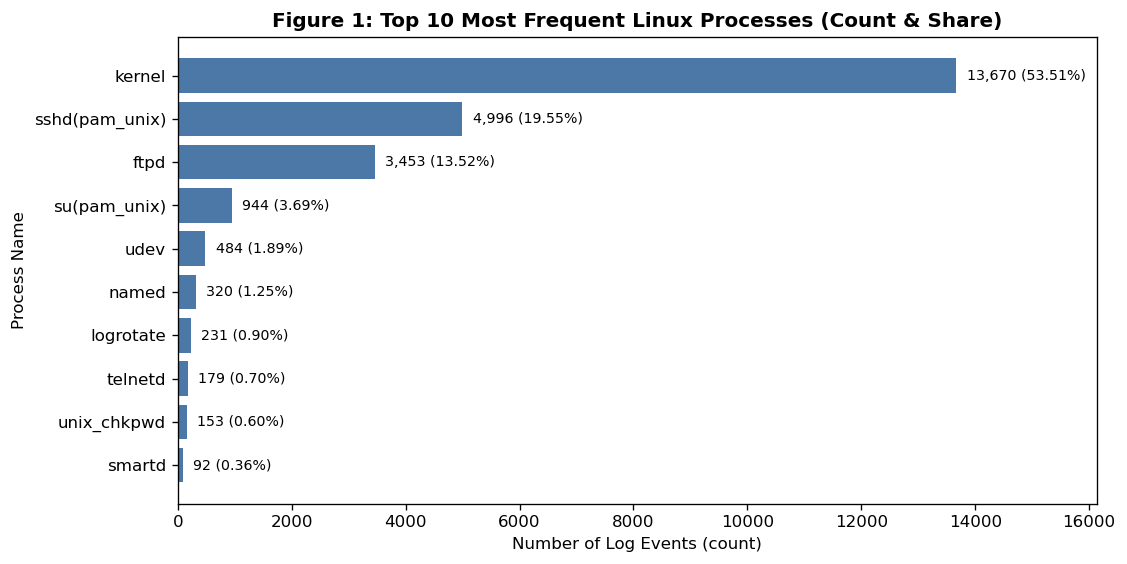

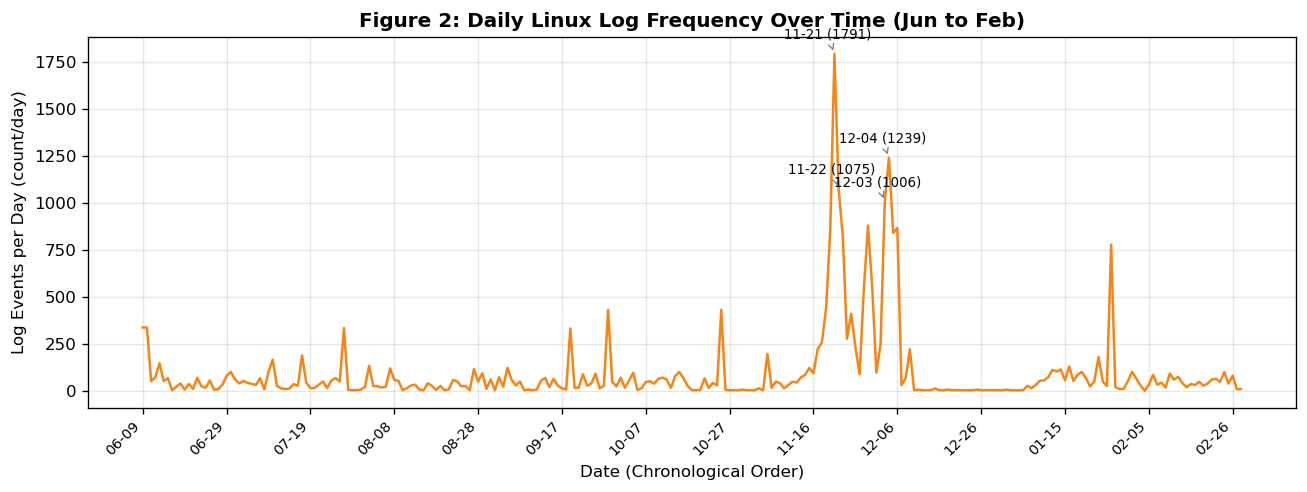

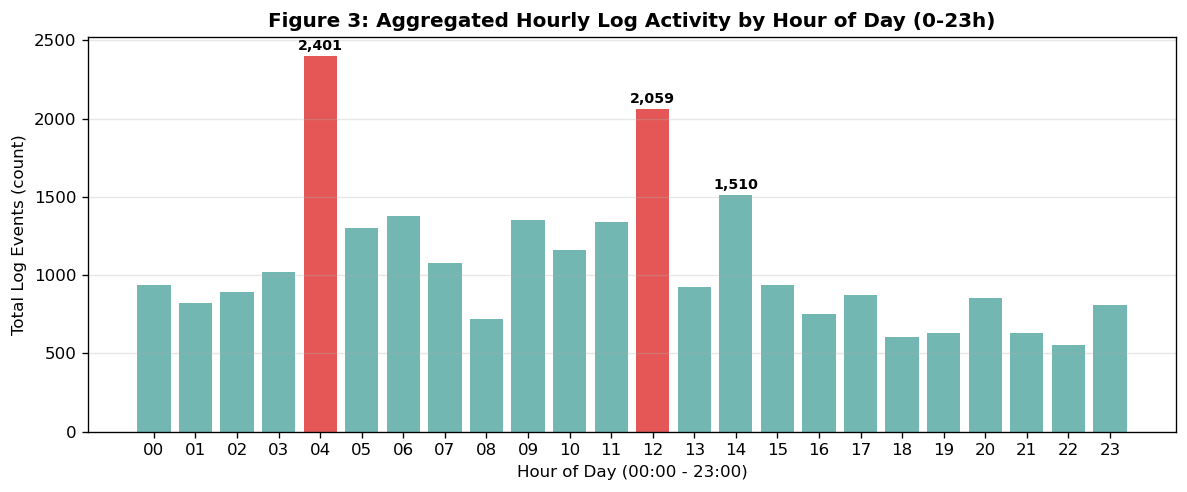

成員 1 三張核心圖表已全部產出完成！


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 120

# 1. 讀取組內既有的三個統計檔
proc_df = pd.read_csv("process_frequency.csv")
daily_df = pd.read_csv("daily_frequency.csv")
hourly_df = pd.read_csv("hourly_frequency.csv")

total_logs = proc_df["count"].sum()
proc_df["pct"] = proc_df["count"] / total_logs * 100

# --- 圖 1：前 10 大最頻繁程序排名與比例圖 ---
top10 = proc_df.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.barh(top10["process"], top10["count"], color="#4C78A8")
ax.set_title("Figure 1: Top 10 Most Frequent Linux Processes (Count & Share)", fontsize=12, fontweight="bold")
ax.set_xlabel("Number of Log Events (count)")
ax.set_ylabel("Process Name")
for i, (cnt, pct) in enumerate(zip(top10["count"], top10["pct"])):
    ax.text(cnt + 180, i, f"{cnt:,} ({pct:.2f}%)", va="center", fontsize=8.5)
ax.set_xlim(0, top10["count"].max() * 1.18)
plt.tight_layout()
plt.savefig("m1_fig1_process_ranking.png", dpi=150)
plt.show()

# --- 圖 2：各日期活動趨勢與高峰（依真實跨年時序 Jun -> Feb 排序）---
daily_df["month"] = daily_df["day"].str[:2].astype(int)
daily_df["sort_order"] = daily_df["month"].apply(lambda m: m if m >= 6 else m + 12)
daily_sorted = daily_df.sort_values(["sort_order", "day"]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(range(len(daily_sorted)), daily_sorted["count"], color="#F58518", linewidth=1.5)
ax.set_title("Figure 2: Daily Linux Log Frequency Over Time (Jun to Feb)", fontsize=12, fontweight="bold")
ax.set_xlabel("Date (Chronological Order)")
ax.set_ylabel("Log Events per Day (count/day)")
step = 20
ax.set_xticks(range(0, len(daily_sorted), step))
ax.set_xticklabels(daily_sorted["day"].iloc[::step], rotation=45, ha="right", fontsize=8.5)

# 標註前 4 大高峰日
for _, row in daily_sorted.nlargest(4, "count").iterrows():
    idx = row.name
    ax.annotate(f"{row['day']} ({row['count']})", xy=(idx, row["count"]),
                xytext=(idx - 12, row["count"] + 80), fontsize=8,
                arrowprops=dict(arrowstyle="->", color="gray", lw=0.8))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("m1_fig2_daily_frequency.png", dpi=150)
plt.show()

# --- 圖 3：24 小時（0-23時）活動分布圖 ---
hourly_df["hour_of_day"] = hourly_df["hour"].str.extract(r"\s(\d{2}):00").astype(int)
hod = hourly_df.groupby("hour_of_day")["count"].sum().reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4.2))
colors = ["#E45756" if h in [4, 12] else "#72B7B2" for h in hod.index]
ax.bar(hod.index, hod.values, color=colors)
ax.set_title("Figure 3: Aggregated Hourly Log Activity by Hour of Day (0-23h)", fontsize=12, fontweight="bold")
ax.set_xlabel("Hour of Day (00:00 - 23:00)")
ax.set_ylabel("Total Log Events (count)")
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}" for h in range(24)])
for h, v in hod.items():
    if h in [4, 12, 14]:
        ax.text(h, v + 40, f"{v:,}", ha="center", fontsize=8.5, fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("m1_fig3_hourly_distribution.png", dpi=150)
plt.show()

print("成員 1 三張核心圖表已全部產出完成！")

# RQ1 分析報告：Linux 系統程序分布與時間活動模式（成員 1）

* **負責人**：成員 1（姜羽芯 / 1140352）
* **資料來源**：[Loghub Linux 系統日誌](https://github.com/logpai/loghub/tree/master/Linux)（取自專題儲存庫 [OS-Final-Project](https://github.com/yiqiaolin/OS-Final-Project) 之 `linux_analysis/`：`process_frequency.csv`、`daily_frequency.csv`、`hourly_frequency.csv`）
* **資料規模**：共 **25,549** 筆成功解析日誌、涵蓋 **72** 種程序、橫跨 **263** 天（時間順序自 `06-09` 至隔年 `02-28`）、共 **1,124** 個有活動的「日期－小時」區段。

## 1. 最頻繁系統程序排名與作業系統行為

前 3 大程序合計占總日誌量 **86.58%**，前 5 大合計占 **92.16%**，顯示 Linux 伺服器日誌高度集中於「核心層事件」與「外部網路認證／連線服務」。

| 排名 | 程序名稱 | 日誌筆數 | 占比 | 對應作業系統行為說明 |
| :--- | :--- | ---: | ---: | :--- |
| 1 | `kernel` | 13,670 | 53.51% | 作業系統核心層活動，涵蓋記憶體管理（含 OOM 機制）、排程、硬體／驅動與系統狀態回報，是最主要的日誌來源。 |
| 2 | `sshd(pam_unix)` | 4,996 | 19.55% | SSH 遠端登入透過 PAM 模組進行身分驗證與 session 建立／關閉，為遠端存取與暴力破解偵測（RQ2）的核心對象。 |
| 3 | `ftpd` | 3,453 | 13.52% | FTP 檔案傳輸服務之連線與存取紀錄，反映頻繁的外部檔案服務請求。 |
| 4 | `su(pam_unix)` | 944 | 3.69% | 使用者切換身分／提權驗證紀錄，常見於系統例行排程切換特定帳號執行維護任務。 |
| 5 | `udev` | 484 | 1.89% | 裝置節點管理守護程序，負責動態偵測與配置系統硬體裝置。 |
| 6 | `named` | 320 | 1.25% | BIND DNS 名稱解析服務運作與查詢紀錄。 |
| 7 | `logrotate` | 231 | 0.90% | 系統日誌自動輪替、壓縮與清理作業，屬週期性系統維護行為。 |
| 8 | `telnetd` | 179 | 0.70% | Telnet 遠端終端機連線服務紀錄。 |
| 9 | `unix_chkpwd` | 153 | 0.60% | PAM 密碼檢查輔助程式，協助驗證系統帳號密碼。 |
| 10 | `smartd` | 92 | 0.36% | 硬碟 S.M.A.R.T. 健康狀態定期監控守護程序。 |

## 2. 每日日誌量變化與異常高峰（`06-09` 至 `02-28`）

將原始資料依真實時序（6 月至隔年 2 月）排序後，平日多數日期的日誌量維持在數十至兩百餘筆的低基線，但在 **11 月下旬至 12 月初**出現明顯的連續高載群聚，且隔年 **1 月下旬**出現單日孤立尖峰。

* **主要集中高峰期（`11-20` ～ `12-06`）**：全資料集前 10 高日誌量日期中，有 **9 天**落在此區間，包括 `11-21`（**1,791** 筆，全期最高）、`12-04`（**1,239** 筆）、`11-22`（**1,075** 筆）、`12-03`（**1,006** 筆）、`11-29`（**879** 筆）、`12-06`（**866** 筆）、`11-20`（**856** 筆）、`12-05`（**841** 筆）與 `11-23`（**819** 筆）。這類跨日連續暴增代表系統在該期間承受持續性的外部連線嘗試、認證失敗潮或核心壓力，而非單純日常背景事件。
* **單日孤立尖峰（`01-26`）**：當日總量達 **778** 筆（全期第 10 高），與前後多數維持在數十筆的日子形成強烈對比，屬於典型的短時間突發事件。

## 3. 各小時活動分布與單一小時突發尖峰（00:00 ～ 23:00）

將 263 天的每小時紀錄加總至 00～23 時後，系統活動呈現「**凌晨例行維護高峰**」與「**日間突發事件推升**」兩種截然不同的作業系統行為模式。

* **凌晨 04:00 高峰（2,401 筆，全天最高）**：反映 Linux 系統預設的每日背景維護排程（如 `cron.daily` 觸發 `logrotate` 日誌輪替、系統清理與 `su(pam_unix)` 帳號切換），屬於**穩定且具週期性的例行 OS 行為**。
* **中午 12:00 次高峰（2,059 筆）與 14:00（1,510 筆）**：主要受少數極端單小時突發事件拉高，例如 **`01-26 12:00`** 單小時即產生 **713 筆**日誌（占 `01-26` 全日 778 筆的 **91.6%**），**`12-06 12:00`** 亦達 **388 筆**；其餘高密度單小時尖峰還包含 `10-25 10:00`（368 筆）、`09-28 09:00`（367 筆）、`06-09 06:00`（308 筆）、`06-10 11:00`（299 筆）、`07-27 14:00`（299 筆）與 `09-19 05:00`（295 筆）。
* **日間其餘時段（05:00 ～ 11:00）**：維持在 1,100 ～ 1,400 筆之間（如 `06:00` 1,376 筆、`09:00` 1,355 筆、`11:00` 1,342 筆）；傍晚至深夜（18:00 ～ 22:00）則相對較低（約 550 ～ 850 筆）。

## 4. RQ1 小結與對後續 RQ2／RQ3 的銜接

1. **程序結構高度集中**：`kernel`（53.51%）、`sshd(pam_unix)`（19.55%）與 `ftpd`（13.52%）合計占 86.58%，顯示核心運作與遠端服務驗證主導整體日誌量。
2. **區分「週期性維護」與「非預期突發」**：`04:00` 的高峰屬 Linux 例行維護排程；相對地，`11-20` ～ `12-06` 的連續高載與 `01-26 12:00`（713 筆／小時）等極端尖峰屬於非週期性突發，可直接交由成員 2～4 在 RQ1 模板分析與 RQ2（SSH 暴力嘗試、OOM 與高密度突發視窗）進一步驗證成因。